# EcoData · Sesión 12 (U2): Lambda de calidad del aire y clima en Juliaca
**Equipo EcoData** — Lanzeloth Vargas Marichi · Alahin Reyme Ticona Veliz · Big Data, UPeU

Flujo completo, ejecutable desde Jupyter:

`Open-Meteo API → Kafka (atmos-aire / atmos-clima) → Spark Structured Streaming + modelo GBT (MLlib) → Pushgateway → Prometheus → Grafana`

| Sección | Qué demuestra |
|---|---|
| 1 | Conexión con la API |
| 2 | Contrato del evento |
| 3 | Publicar en Kafka |
| 4 | Verificar y contar eventos en Kafka |
| 5 | Modelo: predicción de la próxima hora |
| 6 | Jobs de streaming (iniciar / estado) |
| 7 | Métricas en Prometheus |
| 8 | Desconectar |

> Ejecuta las celdas en orden. Requiere Kafka, Pushgateway y Prometheus levantados (Docker).

## 0. Preparación

In [1]:
import sys, json, time, subprocess, urllib.request, urllib.parse
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire, clima_comun as clima
import openmeteo_a_kafka as pub_aire, openmeteo_clima_a_kafka as pub_clima

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
print("Scripts del proyecto cargados desde /tmp/s12/scripts")

from kafka import KafkaConsumer, TopicPartition
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP)
print("Kafka OK. Topics:", sorted(t for t in c.topics() if t.startswith("atmos")))
c.close()

Scripts del proyecto cargados desde /tmp/s12/scripts
Kafka OK. Topics: ['atmos-aire', 'atmos-clima', 'atmos-eventos', 'atmos-negocio', 'atmos-real']


## 1. Conexión con la API (Open-Meteo)
Open-Meteo entrega datos **horarios y modelados** (CAMS ~45 km para aire; reanálisis/pronóstico para clima), no sensores en vivo. El procesamiento es en tiempo real; la fuente se actualiza cada hora.

In [2]:
import pandas as pd
serie = pub_aire.desde_api()          # [(ts_ms, pm25, pm10)] hasta la hora actual
df_aire = pd.DataFrame(serie, columns=["ts_ms","pm25","pm10"])
df_aire["hora_UTC"] = pd.to_datetime(df_aire.ts_ms, unit="ms")
print(f"{len(df_aire)} horas recibidas de la API · último dato: {df_aire.hora_UTC.iloc[-1]}")
df_aire.tail(8)

68 horas recibidas de la API · último dato: 2026-11-04 19:00:00


,ts_ms,pm25,pm10,hora_UTC
60,1793793600000,5.5,10.4,2026-11-04 12:00:00
61,1793797200000,5.1,11.8,2026-11-04 13:00:00
62,1793800800000,5.2,12.3,2026-11-04 14:00:00
63,1793804400000,4.4,10.2,2026-11-04 15:00:00
64,1793808000000,3.5,7.5,2026-11-04 16:00:00
65,1793811600000,3.1,6.0,2026-11-04 17:00:00
66,1793815200000,2.8,5.2,2026-11-04 18:00:00
67,1793818800000,2.5,4.6,2026-11-04 19:00:00


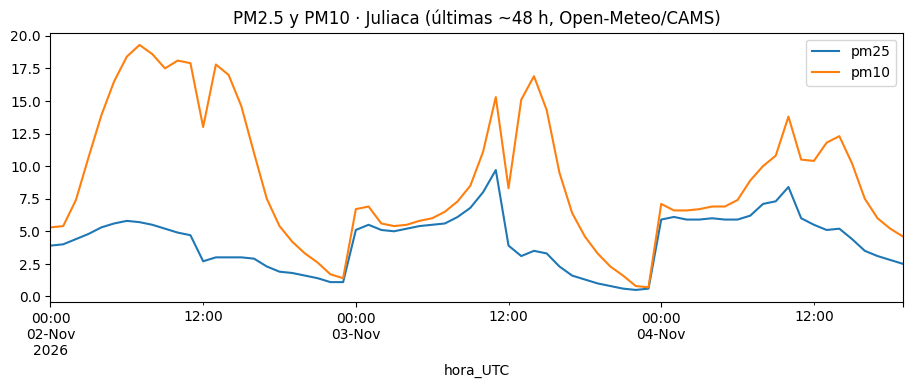

In [3]:
df_aire.set_index("hora_UTC")[["pm25","pm10"]].plot(figsize=(11,3.5), title="PM2.5 y PM10 · Juliaca (últimas ~48 h, Open-Meteo/CAMS)");

## 2. Contrato del evento
Cada fila de la API se convierte en un evento JSON con el mismo esquema que lee Spark (`ESQUEMA`).

In [4]:
print("Esquema Spark:", aire.ESQUEMA)
ts, p25, p10 = serie[-1]
print(json.dumps(aire.evento(ts, p25, p10, "openmeteo-cams"), indent=2))

Esquema Spark: tipoEvento STRING, sensorId STRING, pm25 DOUBLE, pm10 DOUBLE, origen STRING, timestamp LONG
{
  "tipoEvento": "aire.lectura",
  "sensorId": "openmeteo-cams-juliaca",
  "pm25": 2.5,
  "pm10": 4.6,
  "origen": "openmeteo-cams",
  "timestamp": 1793818800000
}


## 3. Publicar en Kafka
Equivale a `openmeteo_a_kafka.py --api`, pero desde Jupyter.

In [21]:
from kafka import KafkaProducer
prod = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", linger_ms=20,
                     key_serializer=str.encode, value_serializer=lambda v: json.dumps(v).encode())
def publicar_aire():
    ev = [aire.evento(t, a, b, "openmeteo-cams") for t, a, b in pub_aire.desde_api()]
    for e in ev: prod.send("atmos-aire", key=e["sensorId"], value=e)
    prod.flush(); return len(ev)
print(publicar_aire(), "eventos de aire -> atmos-aire")

69 eventos de aire -> atmos-aire


In [6]:
# Clima: misma lógica con su propio contrato
sc = pub_clima.desde_api()
ev_c = [clima.evento(*fila, "openmeteo-clima") for fila in sc]   # fila = (ts, temp, hum, viento)
print(len(ev_c), "filas de clima de la API. Ejemplo:"); print(json.dumps(ev_c[-1], indent=2))

68 filas de clima de la API. Ejemplo:
{
  "tipoEvento": "clima.lectura",
  "sensorId": "openmeteo-clima-juliaca",
  "temp": 19.4,
  "hum": 25.0,
  "viento": 13.7,
  "origen": "openmeteo-clima",
  "timestamp": 1793818800000
}


In [22]:
for e in ev_c: prod.send("atmos-clima", key=e["sensorId"], value=e)
prod.flush(); print(len(ev_c), "eventos de clima -> atmos-clima")

68 eventos de clima -> atmos-clima


## 4. Verificar y contar eventos en Kafka

In [8]:
def contar(topic):
    c = KafkaConsumer(bootstrap_servers=BOOTSTRAP)
    tps = [TopicPartition(topic, p) for p in c.partitions_for_topic(topic)]
    ini, fin = c.beginning_offsets(tps), c.end_offsets(tps); c.close()
    return sum(fin[t]-ini[t] for t in tps)
for t in ["atmos-aire","atmos-clima","atmos-negocio"]:
    print(f"{t:15s} {contar(t):>8,} eventos")

atmos-aire        12,776 eventos
atmos-clima       12,711 eventos
atmos-negocio        878 eventos


In [9]:
# Últimos 3 mensajes de atmos-aire
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP, auto_offset_reset="latest", consumer_timeout_ms=3000)
tp = [TopicPartition("atmos-aire", p) for p in c.partitions_for_topic("atmos-aire")]
c.assign(tp); fin = c.end_offsets(tp)
for t in tp: c.seek(t, max(0, fin[t]-3))
for m in c: print(m.offset, m.value.decode())
c.close()

12773 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 3.1, "pm10": 6.0, "origen": "openmeteo-cams", "timestamp": 1793811600000}
12774 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 2.8, "pm10": 5.2, "origen": "openmeteo-cams", "timestamp": 1793815200000}
12775 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 2.5, "pm10": 4.6, "origen": "openmeteo-cams", "timestamp": 1793818800000}


## 5. Modelo: predicción de PM2.5 de la próxima hora
GBT de MLlib (PipelineModel). Predice el **delta** a +1 h; la predicción es `pm25_actual + delta`. Se compara contra la *persistencia* (decir que la próxima hora será igual).

In [23]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[1]").appName("nb_ecodata").config("spark.ui.enabled","false").getOrCreate()
from pyspark.ml import PipelineModel
modelo = PipelineModel.load("/tmp/s12/modelo_pm25")
meta = json.load(open("/tmp/s12/modelo_pm25/meta.json")); print("Meta del modelo:", meta)

hist = {t:(a,b) for t,a,b in serie}
t_ult = max(t for t in hist if aire.features(hist, t))     # última hora con 24 h de historia
f = aire.features(hist, t_ult)
pred = modelo.transform(spark.createDataFrame([{k: float(v) for k,v in f.items()}])).select("prediction").first()[0]
actual = hist[t_ult][0]
print(f"Hora base (UTC): {pd.to_datetime(t_ult, unit='ms')}")
print(f"PM2.5 actual: {actual:.2f} µg/m³ · delta predicho: {pred:+.2f} · PM2.5 próxima hora: {actual+pred:.2f} µg/m³")
umbral = float(meta["umbral_relativo_p95"]); print("Umbral de episodio (p95 entrenamiento):", umbral, "µg/m³")

Meta del modelo: {'persistencia_mae': 0.6871207784773903, 'lineal_mae': 0.7419191622745201, 'gbt_mae': 0.4733888743356669, 'mejora_vs_persistencia_pct': 31.105434566443726, 'umbral_relativo_p95': 10.5, 'n_train': 6988, 'n_test': 1747, 'features': ['l0', 'd1', 'd3', 'd24', 'm24', 'pm10d', 'hs', 'hc'], 'test_desde': 1697774400000, 'unidad': 'ug/m3', 'fuente': 'Open-Meteo Air Quality (CAMS, modelado, ~45 km)'}
Hora base (UTC): 2026-11-04 19:00:00
PM2.5 actual: 2.50 µg/m³ · delta predicho: +0.07 · PM2.5 próxima hora: 2.57 µg/m³
Umbral de episodio (p95 entrenamiento): 10.5 µg/m³


## 6. Jobs de streaming
Spark lee de Kafka, calcula ventanas de 6 h con watermark de 2 h, infiere y empuja métricas al Pushgateway. **Un solo job por tipo** (duplicados generan conflictos).

In [11]:
def jobs_activos():
    out = subprocess.run("ps aux | grep s12_streaming | grep -v grep", shell=True, capture_output=True, text=True).stdout
    return [l for l in out.splitlines() if "spark-submit" in l or "SparkSubmit" in l]
print("Procesos spark activos:", len(jobs_activos()))

Procesos spark activos: 0


In [12]:
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"
def lanzar(nombre, script, modelo_dir):
    log = open(f"/tmp/s12/{nombre}.log", "w")
    return subprocess.Popen(["spark-submit","--packages",PKG,f"/tmp/s12/scripts/{script}","--modelo",modelo_dir,"--limpiar"],
                            stdout=log, stderr=subprocess.STDOUT)
# Ejecuta SOLO si no hay jobs activos (celda anterior = 0)
JOBS = {}
JOBS["aire"]  = lanzar("job_aire",  "s12_streaming_aire.py",  "/tmp/s12/modelo_pm25")
JOBS["clima"] = lanzar("job_clima", "s12_streaming_clima.py", "/tmp/s12/modelo_temp")
print({k: v.pid for k,v in JOBS.items()})

{'aire': 276, 'clima': 277}


In [13]:
# Estado y últimas líneas del log
for k,p in JOBS.items(): print(k, "corriendo" if p.poll() is None else f"terminó ({p.returncode})")
print(subprocess.run("tail -n 8 /tmp/s12/job_aire.log", shell=True, capture_output=True, text=True).stdout)

aire corriendo
clima corriendo
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   11  |   0   |   0   |   0   ||   11  |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-a4310573-3b3f-4b52-8600-4c5d1ab53452
	confs: [default]
	0 artifacts copied, 11 already retrieved (0kB/15ms)



## 7. Métricas en Prometheus (lo mismo que ve Grafana)

In [16]:
def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception as e: err = e
    raise err
for nombre, q in [("Frescura aire (s)",'time()-push_time_seconds{job="lambda26_aire",instance="inferencia"}'),
                  ("Frescura clima (s)",'time()-push_time_seconds{job="lambda26_clima",instance="inferencia"}'),
                  ("MAE modelo aire",'lambda26_aire_mae_modelo'),("MAE persistencia aire",'lambda26_aire_mae_persistencia')]:
    try:
        r = prom(q); print(f"{nombre:26s}", [round(float(x['value'][1]),3) for x in r] or "sin datos")
    except Exception as e: print(nombre, "->", e)

Frescura aire (s)          [739.154]
Frescura clima (s)         [740.104]
MAE modelo aire            [0.446]
MAE persistencia aire      [0.587]


In [17]:
# Alternativa directa: leer el Pushgateway
txt = urllib.request.urlopen(PUSHGATEWAY + "/metrics", timeout=4).read().decode()
print("\n".join(l for l in txt.splitlines() if l.startswith("lambda26_") and not l.startswith("#"))[:3000])

lambda26_aire_episodios_total{instance="inferencia",job="lambda26_aire"} 247
lambda26_aire_estado_filas{instance="streaming",job="lambda26_aire"} 4
lambda26_aire_eventos_total{instance="inferencia",job="lambda26_aire"} 12771
lambda26_aire_filas_descartadas_watermark_total{instance="streaming",job="lambda26_aire"} 0
lambda26_aire_input_rows_per_second{instance="streaming",job="lambda26_aire"} 0
lambda26_aire_lote_id{instance="inferencia",job="lambda26_aire"} 0
lambda26_aire_lote_ventanas{instance="streaming",job="lambda26_aire"} 1
lambda26_aire_mae_modelo{instance="inferencia",job="lambda26_aire"} 0.44602000984686907
lambda26_aire_mae_persistencia{instance="inferencia",job="lambda26_aire"} 0.5874853801169597
lambda26_aire_mejora_pct{instance="inferencia",job="lambda26_aire"} 24.07981118473569
lambda26_aire_n_evaluadas{instance="inferencia",job="lambda26_aire"} 855
lambda26_aire_pm10_ultimo{instance="inferencia",job="lambda26_aire"} 4.6
lambda26_aire_pm25_ultimo{instance="inferencia",job

**Dashboard Grafana:** http://localhost:43000/d/lambda26-s12-ecodata (admin / admin) · **Prometheus:** http://localhost:49090 · **Kafka UI:** http://localhost:48085

## 8. Desconectar (dejar de recibir datos)
Orden recomendado: 1) fuente (no publicar más), 2) jobs Spark, 3) conexiones Kafka.

In [ ]:
# 1) Fuente: cerrar el productor. Si hay un bucle en CMD, detenerlo con Ctrl+C en esa ventana.
prod.flush(); prod.close(); print("Productor Kafka cerrado: ya no se publican datos.")

In [ ]:
# 2) Detener los jobs de streaming
for k,p in JOBS.items():
    if p.poll() is None: p.terminate()
time.sleep(3); print("Procesos activos:", len(jobs_activos()))
spark.stop()

> Al detener los jobs el semáforo de Grafana pasa a rojo: no llegan eventos nuevos. El histórico en Prometheus se conserva (volumen Docker).
> **No** uses `docker compose down -v` ni `docker volume prune`: borran el histórico.